# Lab 05 — Post-Training: Turning a Base Model Into an Assistant
### Supervised answers, preference learning, and reward-driven updates

**English · CPU practical · Three sessions of 90–120 minutes**

This lab continues from the file checkpoint produced by Lab 3. It follows the complete Step 5 topic sequence in FareedKhan-dev's repository. The teaching approach uses mathematical derivations, small implementations, and behavioral checks inspired by Stanford CS336's component-building approach. This is independently authored teaching material.

**Practical scope:** train a small SFT model, train a reward head on preference pairs, train a DPO policy, calculate PPO advantages and perform an actor-critic update, and run a short GRPO experiment. Compact arithmetic prompts fit the 24-character context of the Lab 3 model. These are controlled algorithm exercises. General assistant quality requires a stronger base, broader data, and independent evaluation.

| Stage | Data | Learned component | Signal |
|---|---|---|---|
| SFT | prompt + correct completion | policy | masked token NLL |
| Reward model | chosen/rejected pair | scalar reward head and optionally backbone | preference ranking |
| DPO family | preferences or desirability labels | policy | relative response likelihood |
| PPO | generated trajectories and rewards | actor + critic | estimated advantages |
| GRPO / RLVR | groups of sampled answers | policy | group-relative verifiable reward |

Read the explanations before running each implementation. The complete reference path runs top to bottom; independent exercises are near the end.

**Sources inspected 14 November 2026**
- [Step 5](https://github.com/FareedKhan-dev/train-llm-from-scratch#step-5-post-training-turning-a-base-model-into-an-assistant)
- [SFT](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/sft.py)
- [Preference objectives](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/dpo.py), blob `14d36bc8bdba4d498599c6eb1076a46ced3d80fd`
- [PPO](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/ppo.py)
- [GRPO](https://github.com/FareedKhan-dev/train-llm-from-scratch/blob/main/src/post_training/grpo.py), blob `fb02e5c74bb6db0f0895ab8be52e8b7c7ed375dc`
- [Stanford CS336](https://cs336.stanford.edu/spring2025/)

## Executed CPU reference and interpretation

All 13 code cells completed using the actual Lab 3 checkpoint and PyTorch 2.15.0+cpu. The notebook contains the resulting outputs and SFT curve.

| Measurement | Observed result |
|---|---|
| SFT training exact match | 100% |
| SFT held-out exact match | 0% on four pairs |
| SFT held-out EOT rate | 100% |
| Reward head preference accuracy | 83.3% train, 25% validation |
| DPO implicit preference accuracy | 100% train, 25% validation |
| GRPO constrained held-out accuracy | 0% |

These results reveal overfitting and limited transfer in the tiny base model. Validation NLL reaches its lowest recorded value early and then rises while training loss falls. The fixed 300-update SFT run intentionally makes that failure mode visible; model selection in a larger experiment should compare validation checkpoints. The fully fitted SFT policy also makes almost all training GRPO groups receive identical rewards, leaving little reward-driven gradient. An extension is to start RL from an earlier SFT checkpoint and measure the fraction of groups with nonzero reward variance.

This practical demonstrates implementations and diagnoses their limits. It does not establish general assistant or reasoning capability.


## 1. Load the Lab 3 checkpoint

Install `torch` and `matplotlib` if needed. Keep `lab03_runs` beside your notebooks or set `CHECKPOINT_PATH` explicitly. The default selects the newest `final.pt` by modification time. No weights are embedded here.

Lab 3's ASCII vocabulary already contains all characters used below. The compact format is `U:1+2
A:` followed by `3` and EOT. The repository uses textual role markers such as `<|user|>` and `<|assistant|>`. Our shorter teaching format fits the existing context without adding position embeddings or changing the vocabulary.


In [1]:
import copy
import json
import math
import tempfile
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F

torch.manual_seed(42)
torch.set_num_threads(1)
CHECKPOINT_PATH = None
if CHECKPOINT_PATH is None:
    candidates = sorted(Path("lab03_runs").glob("*/final.pt"), key=lambda p: p.stat().st_mtime)
    if not candidates:
        raise FileNotFoundError("Run Lab 3 first or set CHECKPOINT_PATH to its final.pt.")
    CHECKPOINT_PATH = candidates[-1]
checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)
if checkpoint.get("tokenizer") != {"kind":"ascii-character", "vocab_size":129, "eot_id":128}:
    raise ValueError("This practical requires the Lab 3 ASCII tokenizer.")
config = checkpoint["config"]
EOT, V = 128, 129
Path("lab05_runs").mkdir(exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="run_", dir="lab05_runs"))
print("Checkpoint:", CHECKPOINT_PATH)
print("PyTorch:", torch.__version__, "| outputs:", RUN_DIR)


Checkpoint: lab03_runs/run_pvg4r57e/final.pt
PyTorch: 2.15.0+cpu | outputs: /workspace/scratch/d20f4a09d498/lab05_runs/run_46tulole


In [2]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.hidden = nn.Linear(width, 4 * width)
        self.proj = nn.Linear(4 * width, width)

    def forward(self, x):
        return self.proj(F.relu(self.hidden(x)))

def causal_attention(q, k, v):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    length = q.shape[-2]
    allowed = torch.ones(length, length, dtype=torch.bool, device=q.device).tril()
    weights = scores.masked_fill(~allowed, float("-inf")).softmax(dim=-1)
    return weights @ v, weights

class Head(nn.Module):
    def __init__(self, width, head_width):
        super().__init__()
        self.query = nn.Linear(width, head_width, bias=False)
        self.key = nn.Linear(width, head_width, bias=False)
        self.value = nn.Linear(width, head_width, bias=False)

    def forward(self, x):
        output, _ = causal_attention(self.query(x), self.key(x), self.value(x))
        return output

class MultiHeadAttention(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        if width % heads:
            raise ValueError("Embedding width must be divisible by head count.")
        self.heads = nn.ModuleList([Head(width, width // heads) for _ in range(heads)])
        self.proj = nn.Linear(width, width)

    def forward(self, x):
        return self.proj(torch.cat([head(x) for head in self.heads], dim=-1))

class Block(nn.Module):
    def __init__(self, width, heads):
        super().__init__()
        self.ln1 = nn.LayerNorm(width)
        self.attn = MultiHeadAttention(width, heads)
        self.ln2 = nn.LayerNorm(width)
        self.mlp = MLP(width)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class Transformer(nn.Module):
    def __init__(self, vocab_size, width, heads, context_length, layers):
        super().__init__()
        self.context_length = context_length
        self.token_embed = nn.Embedding(vocab_size, width)
        self.position_embed = nn.Embedding(context_length, width)
        self.blocks = nn.ModuleList([Block(width, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(width)
        self.lm_head = nn.Linear(width, vocab_size)

    def forward_hidden(self, ids):
        length = ids.shape[1]
        if not 1 <= length <= self.context_length:
            raise ValueError("Sequence length is outside the supported context.")
        positions = torch.arange(length, device=ids.device)
        hidden = self.token_embed(ids) + self.position_embed(positions)
        for block in self.blocks:
            hidden = block(hidden)
        return self.norm(hidden)

    def forward(self, ids, targets=None):
        logits = self.lm_head(self.forward_hidden(ids))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), targets.reshape(-1).long())
        return logits, loss


In [3]:
base = Transformer(V, config["width"], config["heads"], config["context_length"], config["layers"])
base.load_state_dict(checkpoint["model_state"], strict=True)
base.eval()

def frozen_copy(model):
    result = copy.deepcopy(model).eval()
    result.requires_grad_(False)
    return result

examples = [(a,b) for a in range(4) for b in range(4)]
validation = [(0,1),(1,3),(2,2),(3,0)]
training = [pair for pair in examples if pair not in validation]

def prompt(a,b):
    return f"U:{a}+{b}\nA:"

def encode_chat(a,b,answer):
    header = [ord(c) for c in prompt(a,b)]
    response = [ord(c) for c in str(answer)] + [EOT]
    ids = header + response
    if len(ids) > config["context_length"]:
        raise ValueError("Example exceeds the trained context.")
    return torch.tensor(ids), torch.tensor([0]*len(header)+[1]*len(response), dtype=torch.float32)

def batch_pairs(pairs, rejected=False):
    records = [encode_chat(a,b,(a+b+1)%7 if rejected else a+b) for a,b in pairs]
    return torch.stack([r[0] for r in records]), torch.stack([r[1] for r in records])

train_ids, train_mask = batch_pairs(training)
val_ids, val_mask = batch_pairs(validation)
print("Training examples:",len(training),"| validation:",len(validation))
print("Example:",repr(prompt(1,2)+"3<EOT>"))


Training examples: 12 | validation: 4
Example: 'U:1+2\nA:3<EOT>'


## 2. SFT: align the target and loss mask

For logits at input position $t$, the target is token $t+1$. Therefore shift token IDs and the assistant mask together:

$$\mathcal L_{SFT}=-\frac{\sum_{b,t}m_{b,t+1}\log\pi_\theta(x_{b,t+1}\mid x_{b,\le t})}{\sum_{b,t}m_{b,t+1}}.$$

The prompt contributes context. The assistant answer and its EOT contribute supervised targets. Role headers have mask zero. Masking the prompt's direct loss does not stop gradients from flowing through its contextual representations.

The demonstration uses equal-length records and needs no padding. With padding, set the corresponding loss mask to zero, maintain causal attention, and ensure reward pooling uses the last real token. Reject batches without any supervised tokens.

**Paper exercise:** For IDs `[10,11,12,13,128]` and mask `[0,0,0,1,1]`, write the shifted target and mask. Answer: targets `[11,12,13,128]`, mask `[0,0,1,1]`.


In [4]:
def token_logps(model, ids):
    logits = model(ids[:, :-1])[0]
    return logits.log_softmax(-1).gather(-1,ids[:,1:].unsqueeze(-1)).squeeze(-1)

def sft_loss(model, ids, mask):
    target_mask = mask[:,1:]
    if target_mask.sum() == 0:
        raise ValueError("No assistant targets.")
    return -(token_logps(model,ids)*target_mask).sum()/target_mask.sum()

def response_logps(model, ids, mask):
    return (token_logps(model,ids)*mask[:,1:]).sum(-1)

sft = copy.deepcopy(base)
optimizer = torch.optim.AdamW(sft.parameters(),lr=0.002,weight_decay=0.01)
sft_curve=[]
for step in range(300):
    sft.train()
    optimizer.zero_grad(set_to_none=True)
    loss = sft_loss(sft,train_ids,train_mask)
    loss.backward()
    nn.utils.clip_grad_norm_(sft.parameters(),1.0)
    optimizer.step()
    if step%30==0 or step==299:
        sft.eval()
        with torch.no_grad():
            row={"update":step+1,"train":sft_loss(sft,train_ids,train_mask).item(),"validation":sft_loss(sft,val_ids,val_mask).item()}
        sft_curve.append(row)
        print(row)
sft.eval()


{'update': 1, 'train': 5.7264227867126465, 'validation': 5.8639960289001465}
{'update': 31, 'train': 0.9918020367622375, 'validation': 1.1563975811004639}
{'update': 61, 'train': 0.31336942315101624, 'validation': 1.71941339969635}
{'update': 91, 'train': 0.031320199370384216, 'validation': 2.2670693397521973}
{'update': 121, 'train': 0.012991759926080704, 'validation': 2.6486542224884033}
{'update': 151, 'train': 0.008363030850887299, 'validation': 2.8583714962005615}
{'update': 181, 'train': 0.00605752831324935, 'validation': 3.015568256378174}
{'update': 211, 'train': 0.004648622591048479, 'validation': 3.1408069133758545}
{'update': 241, 'train': 0.0037056610453873873, 'validation': 3.2459702491760254}
{'update': 271, 'train': 0.0030371583998203278, 'validation': 3.338801622390747}
{'update': 300, 'train': 0.0025574821047484875, 'validation': 3.4184634685516357}


## 3. Evaluate behavior separately from teacher-forced loss

Measure greedy completion accuracy and whether EOT follows the answer. The validation set contains held-out arithmetic pairs but shares the small training distribution. A small model can memorize training pairs without learning addition generally.

The loop below samples no tokens: it uses argmax, keeps the latest trained context, and stops at EOT. Compare the base and SFT checkpoint with identical prompts.


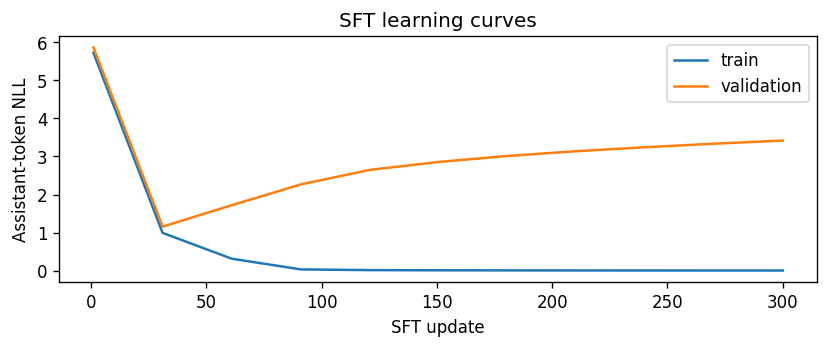

base train exact match: 0.0 EOT rate: 0.0
base validation exact match: 0.0 EOT rate: 0.0
[(0, 1, 'nd a ', False), (1, 3, 'nd a ', False), (2, 2, 'nd a ', False), (3, 0, 'nd a ', False)]
SFT train exact match: 1.0 EOT rate: 1.0
SFT validation exact match: 0.0 EOT rate: 1.0
[(0, 1, '2', True), (1, 3, '3', True), (2, 2, '5', True), (3, 0, '1', True)]


In [5]:
@torch.no_grad()
def answer(model,a,b,budget=5):
    ids=torch.tensor([[ord(c) for c in prompt(a,b)]])
    result=[]
    for _ in range(budget):
        next_id=model(ids[:,-model.context_length:])[0][:,-1].argmax(-1).item()
        if next_id==EOT:
            return "".join(chr(i) for i in result),True
        result.append(next_id)
        ids=torch.cat([ids,torch.tensor([[next_id]])],1)
    return "".join(chr(i) for i in result),False

for name,model in (("base",base),("SFT",sft)):
    for split,pairs in (("train",training),("validation",validation)):
        results=[(a,b,*answer(model,a,b)) for a,b in pairs]
        accuracy=sum(text==str(a+b) for a,b,text,ended in results)/len(results)
        stop_rate=sum(ended for a,b,text,ended in results)/len(results)
        print(name,split,"exact match:",accuracy,"EOT rate:",stop_rate)
        if split=="validation":print(results)
fig,ax=plt.subplots(figsize=(7,3))
for split in ("train","validation"):
    ax.plot([r["update"] for r in sft_curve],[r[split] for r in sft_curve],label=split)
ax.set(xlabel="SFT update",ylabel="Assistant-token NLL",title="SFT learning curves")
ax.legend();fig.tight_layout();plt.show()


## 4. Reward modeling from preference pairs

Attach a scalar linear head to the SFT model's `forward_hidden` output. For a padded sequence, gather at `lengths-1`. A chosen/rejected pair shares the same prompt.

$$P(y_c\succ y_r\mid x)=\sigma(r_\phi(x,y_c)-r_\phi(x,y_r)),$$
$$\mathcal L_{RM}=-\log\sigma(r_c-r_r).$$

Only score differences are identified by this loss. Absolute reward values are not calibrated probabilities. Track held-out preference accuracy and margin. Our synthetic preference labels choose the correct arithmetic digit over a deliberately wrong one. This differs from human preference collection.

The practical freezes the backbone and trains only the scalar head, making the exercise cheap and exposing its capacity limits. The repository trainer can train the reward model more broadly.


In [6]:
class RewardModel(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone=frozen_copy(backbone)
        self.head=nn.Linear(config["width"],1)
    def forward(self,ids,lengths):
        with torch.no_grad():
            hidden=self.backbone.forward_hidden(ids)
        last=hidden[torch.arange(ids.shape[0]),lengths-1]
        return self.head(last).squeeze(-1)

chosen,chosen_mask=batch_pairs(training)
rejected,rejected_mask=batch_pairs(training,rejected=True)
reward_model=RewardModel(sft)
rm_optimizer=torch.optim.AdamW(reward_model.head.parameters(),lr=0.01)
for step in range(120):
    rc=reward_model(chosen,torch.full((len(training),),chosen.shape[1]))
    rr=reward_model(rejected,torch.full((len(training),),rejected.shape[1]))
    rm_loss=-F.logsigmoid(rc-rr).mean()
    rm_optimizer.zero_grad(set_to_none=True)
    rm_loss.backward();rm_optimizer.step()
with torch.no_grad():
    for label,pairs in (("train",training),("validation",validation)):
        c,_=batch_pairs(pairs);r,_=batch_pairs(pairs,True)
        margin=reward_model(c,torch.full((len(pairs),),c.shape[1]))-reward_model(r,torch.full((len(pairs),),r.shape[1]))
        print("Reward model",label,"accuracy:",(margin>0).float().mean().item(),"margin:",margin.mean().item())


Reward model train accuracy: 0.8333333134651184 margin: 0.4228595793247223
Reward model validation accuracy: 0.25 margin: -0.5819143056869507


## 5. DPO: compare the policy against a frozen reference

Let $\ell_\theta(y\mid x)$ be the **sum** of response-token log probabilities, including the response EOT. DPO uses

$$h=(\ell_\theta(y_c)-\ell_\theta(y_r))-(\ell_{ref}(y_c)-\ell_{ref}(y_r)),$$
$$\mathcal L_{DPO}=-\log\sigma(\beta h).$$

At initialization, policy and reference are identical, so $h=0$ and loss is $\log2$. Gradients still encourage the chosen response relative to the rejected one. The reference is a frozen SFT copy; it must not receive gradients or drift during DPO.

Implicit rewards $\beta(\ell_\theta-\ell_{ref})$ provide diagnostics. Their preference accuracy measures relative improvements over the reference, rather than directly proving task accuracy.

**Exercise:** If policy log-probabilities are `(-2,-4)` and reference values are `(-3,-3)`, compute $h$ and the loss for $\beta=0.1$. Expected $h=2$ and loss about 0.5981.


In [7]:
def dpo_loss(pc,pr,rc,rr,beta=0.1):
    return -F.logsigmoid(beta*((pc-pr)-(rc-rr))).mean()

reference=frozen_copy(sft)
dpo=copy.deepcopy(sft)
dpo_optimizer=torch.optim.AdamW(dpo.parameters(),lr=0.0002)
with torch.no_grad():
    ref_chosen=response_logps(reference,chosen,chosen_mask)
    ref_rejected=response_logps(reference,rejected,rejected_mask)
initial=dpo_loss(response_logps(dpo,chosen,chosen_mask),response_logps(dpo,rejected,rejected_mask),ref_chosen,ref_rejected)
assert abs(initial.item()-math.log(2))<1e-5
for step in range(60):
    pc=response_logps(dpo,chosen,chosen_mask)
    pr=response_logps(dpo,rejected,rejected_mask)
    loss=dpo_loss(pc,pr,ref_chosen,ref_rejected)
    dpo_optimizer.zero_grad(set_to_none=True)
    loss.backward();nn.utils.clip_grad_norm_(dpo.parameters(),1.0);dpo_optimizer.step()
with torch.no_grad():
    for split,pairs in (("train",training),("validation",validation)):
        c,cm=batch_pairs(pairs);r,rm=batch_pairs(pairs,True)
        gap=(response_logps(dpo,c,cm)-response_logps(dpo,r,rm))-(response_logps(reference,c,cm)-response_logps(reference,r,rm))
        print("DPO",split,"implicit accuracy:",(gap>0).float().mean().item(),"loss:",(-F.logsigmoid(0.1*gap)).mean().item())
assert all(p.grad is None for p in reference.parameters())


DPO train implicit accuracy: 1.0 loss: 0.5117440819740295
DPO validation implicit accuracy: 0.25 loss: 0.7949670553207397


## 6. ORPO, KTO, IPO, SimPO, and noisy preferences

The repository exposes these through `train_dpo.py --loss_type ...`. Normalization differs by objective, so preserve each function's contract.

| Objective | Main computation | Reference |
|---|---|---|
| ORPO | Chosen mean NLL plus odds-ratio preference penalty | None |
| KTO | Desirable/undesirable utility around a detached KL baseline | Frozen policy |
| IPO | Squared error to a fixed normalized preference gap | Frozen policy |
| SimPO | Average response log-probability margin | None |
| Conservative DPO | Mix original and reversed-label log losses | Frozen policy |

For ORPO, let $a$ be mean response log probability. Its log odds are $a-\log(1-e^a)$. For IPO, the repository uses per-token averages and target gap $1/(2\beta)$. SimPO uses $-\log\sigma(\beta(\bar\ell_c-\bar\ell_r)-\gamma)$.

KTO can use unpaired desirable/undesirable examples. The repository implementation derives both classes from pairs and estimates a nonnegative detached baseline from batch log-ratios. The code below mirrors those scalar computations for inspection.


In [8]:
def preference_variants(pc,pr,rc,rr,nc,nr,beta=0.1):
    ac,ar=pc/nc,pr/nr
    log_odds_c=ac-torch.log(-torch.expm1(ac))
    log_odds_r=ar-torch.log(-torch.expm1(ar))
    orpo=-ac.mean()-F.logsigmoid(log_odds_c-log_odds_r).mean()
    h=(ac-ar)-(rc/nc-rr/nr)
    ipo=((h-1/(2*beta))**2).mean()
    simpo=-F.logsigmoid(2*(ac-ar)-0.5).mean()
    c,r=pc-rc,pr-rr
    baseline=torch.cat([c,r]).mean().clamp_min(0).detach()
    kto=(1-torch.sigmoid(beta*(c-baseline))).mean()+(1-torch.sigmoid(beta*(baseline-r))).mean()
    z=beta*((pc-pr)-(rc-rr))
    conservative=-(0.9*F.logsigmoid(z)+0.1*F.logsigmoid(-z)).mean()
    return dict(orpo=orpo,ipo=ipo,simpo=simpo,kto=kto,conservative_dpo=conservative)

values=preference_variants(torch.tensor([-2.]),torch.tensor([-4.]),torch.tensor([-3.]),torch.tensor([-3.]),torch.tensor([2.]),torch.tensor([2.]))
print({name:value.item() for name,value in values.items()})


{'orpo': 1.2381830215454102, 'ipo': 16.0, 'simpo': 0.20141328871250153, 'kto': 0.950041651725769, 'conservative_dpo': 0.61813884973526}


## 7. PPO: collect, score, estimate, update

PPO keeps three policy roles distinct: the **current** trainable actor, the **old** actor that generated the fixed rollout, and the **reference** used for regularization. A value head estimates expected future return.

For a response trajectory, shape token rewards with a reference penalty and add the terminal task score. With discount $\gamma$ and GAE parameter $\lambda$,

$$\delta_t=r_t+\gamma(1-d_t)V_{t+1}-V_t,$$
$$A_t=\delta_t+\gamma\lambda(1-d_t)A_{t+1},\quad R_t=A_t+V_t.$$

For a genuine terminal EOT, bootstrap value is zero. A length-truncated response needs an explicit terminal/bootstrap convention. Prompt and padding positions must be excluded from response losses.

The PPO ratio is $\rho_t=\exp(\log\pi_\theta-\log\pi_{old})$. Its objective is

$$-\mathbb E[\min(\rho A,\mathrm{clip}(\rho,1-\epsilon,1+\epsilon)A)].$$

Clipping modifies the objective; it does not impose a hard bound on parameter change. Advantages, old log probabilities, and return targets are detached. The value objective can clip new values around old values and use the larger squared error.


In [9]:
def gae(rewards,values,done,gamma=1.0,lam=0.95):
    advantages=torch.zeros_like(rewards)
    running=torch.zeros(rewards.shape[0])
    for t in reversed(range(rewards.shape[1])):
        next_value=values[:,t+1] if t+1<values.shape[1] else torch.zeros_like(running)
        continuation=1-done[:,t]
        delta=rewards[:,t]+gamma*continuation*next_value-values[:,t]
        running=delta+gamma*lam*continuation*running
        advantages[:,t]=running
    return advantages.detach(),(advantages+values).detach()

def clipped_policy_loss(new,old,advantages,clip=0.2):
    ratio=(new-old.detach()).exp()
    return -torch.minimum(ratio*advantages.detach(),ratio.clamp(1-clip,1+clip)*advantages.detach()).mean()

adv,returns=gae(torch.tensor([[0.,0.,1.]]),torch.tensor([[0.2,0.3,0.4]]),torch.tensor([[0.,0.,1.]]),lam=1)
assert torch.allclose(returns,torch.ones_like(returns))
print("GAE advantages:",adv,"returns:",returns)


GAE advantages: tensor([[0.8000, 0.7000, 0.6000]]) returns: tensor([[1.0000, 1.0000, 1.0000]])


## 8. A real actor-critic update in a constrained answer space

The arithmetic exercise permits one answer digit in `{0,...,6}`. We renormalize logits over those seven actions, sample from that distribution, and compute old/new/reference log probabilities under the same restriction. The episode ends after one digit. This is a contextual bandit specialization of PPO, where advantage is reward minus value.

This restriction supplies a dense enough learning signal for our tiny model. Full language rollouts require per-token masks, EOT handling, multi-step credit assignment, and consistent sampling probabilities. The repository implements those pieces in its rollout and PPO trainers.


In [10]:
answer_ids=torch.tensor([ord(str(i)) for i in range(7)])
prompt_batch=torch.tensor([[ord(c) for c in prompt(a,b)] for a,b in training])
gold=torch.tensor([a+b for a,b in training])

def action_logps(policy,prompts):
    return policy(prompts)[0][:,-1,answer_ids].log_softmax(-1)

actor=copy.deepcopy(sft)
value_head=nn.Linear(config["width"],1)
actor_optimizer=torch.optim.AdamW(list(actor.parameters())+list(value_head.parameters()),lr=0.0001)
with torch.no_grad():
    old_distribution=action_logps(actor,prompt_batch)
    actions=torch.multinomial(old_distribution.exp(),1)
    old_logp=old_distribution.gather(1,actions).squeeze(1)
    ref_logp=action_logps(reference,prompt_batch).gather(1,actions).squeeze(1)
    old_value=value_head(actor.forward_hidden(prompt_batch)[:,-1]).squeeze(-1)
    task_reward=(actions.squeeze(1)==gold).float()
    shaped_reward=task_reward-0.02*(old_logp-ref_logp)
    advantages=shaped_reward-old_value
for epoch in range(3):
    new_logp=action_logps(actor,prompt_batch).gather(1,actions).squeeze(1)
    values=value_head(actor.forward_hidden(prompt_batch)[:,-1]).squeeze(-1)
    clipped_values=old_value+(values-old_value).clamp(-0.2,0.2)
    value_loss=0.5*torch.maximum((values-shaped_reward)**2,(clipped_values-shaped_reward)**2).mean()
    policy_loss=clipped_policy_loss(new_logp,old_logp,advantages)
    total=policy_loss+0.5*value_loss
    actor_optimizer.zero_grad(set_to_none=True);total.backward()
    nn.utils.clip_grad_norm_(list(actor.parameters())+list(value_head.parameters()),1.0)
    actor_optimizer.step()
    print("PPO epoch",epoch,"policy loss",policy_loss.item(),"value loss",value_loss.item())


PPO epoch 0 policy loss -1.3016875982284546 value loss 0.9634193778038025
PPO epoch 1 policy loss -1.3016667366027832 value loss 0.8942908644676208
PPO epoch 2 policy loss -1.3015998601913452 value loss 0.8274245262145996


## 9. GRPO and verifiable rewards

GRPO samples $G$ answers for each prompt and replaces the learned critic with group statistics:

$$A_i=(r_i-\bar r)/(s_r+\epsilon).$$

The repository uses PyTorch's sample standard deviation by default, so use group size at least two. An all-equal group has zero centered advantage and supplies no reward-driven policy gradient. A curriculum can increase the chance of obtaining varied rewards.

GRPO applies a clipped policy surrogate and optionally a reference penalty. With $d=\log\pi_{ref}-\log\pi_\theta$, the nonnegative k3 expression is $e^d-d-1$. Its interpretation as an unbiased estimator of $KL(\pi_\theta\|\pi_{ref})$ requires sampling from the current policy with suitable support. Reusing old-policy trajectories changes that sampling condition.

The next experiment uses the same constrained seven-action arithmetic distribution. Groups are laid out contiguously by prompt. Each update collects fresh responses and keeps old log probabilities fixed for its loss calculation.


In [11]:
def group_advantages(rewards):
    return (rewards-rewards.mean(-1,keepdim=True))/(rewards.std(-1,keepdim=True)+1e-4)

assert torch.equal(group_advantages(torch.ones(2,4)),torch.zeros(2,4))
grpo=copy.deepcopy(sft)
grpo_optimizer=torch.optim.AdamW(grpo.parameters(),lr=0.0002)
group_size=8
generator=torch.Generator().manual_seed(91)
grpo_rewards=[]
for step in range(40):
    with torch.no_grad():
        old_all=action_logps(grpo,prompt_batch)
        sampled=torch.multinomial(old_all.exp(),group_size,replacement=True,generator=generator)
        old=old_all.gather(1,sampled)
        ref=action_logps(reference,prompt_batch).gather(1,sampled)
        rewards=(sampled==gold[:,None]).float()
        advantages=group_advantages(rewards)
    new=action_logps(grpo,prompt_batch).gather(1,sampled)
    ratio=(new-old).exp()
    surrogate=torch.minimum(ratio*advantages,ratio.clamp(0.8,1.2)*advantages)
    diff=ref-new
    kl=diff.exp()-diff-1
    loss=(-surrogate+0.02*kl).mean()
    grpo_optimizer.zero_grad(set_to_none=True);loss.backward()
    nn.utils.clip_grad_norm_(grpo.parameters(),1.0);grpo_optimizer.step()
    grpo_rewards.append(rewards.mean().item())
print("GRPO sampled training reward, first/last 10 updates:",sum(grpo_rewards[:10])/10,sum(grpo_rewards[-10:])/10)
with torch.no_grad():
    for name,policy in (("SFT",sft),("GRPO",grpo)):
        vp=torch.tensor([[ord(c) for c in prompt(a,b)] for a,b in validation])
        predicted=action_logps(policy,vp).argmax(-1)
        print(name,"constrained validation accuracy:",(predicted==torch.tensor([a+b for a,b in validation])).float().mean().item())


GRPO sampled training reward, first/last 10 updates: 0.9979166626930237 0.99375
SFT constrained validation accuracy: 0.0
GRPO constrained validation accuracy: 0.0


## 10. Dr. GRPO, DAPO, and GSPO

The repository exposes several precise changes to normalization, clipping, and aggregation. These choices matter for variable-length language responses. Our one-token practical removes length differences, so it cannot demonstrate all their effects.

| Variant | Repository setting | Effect |
|---|---|---|
| Paper-style GRPO aggregation | `seq-mean-token-mean` | Equal weight per nonempty response |
| Repository default aggregation | `token-mean` | Equal weight per valid token |
| Dr. GRPO | `adv_norm none`, `seq-mean-token-sum-norm` | Center rewards without std scaling; constant length denominator |
| DAPO-style configuration | larger upper clip, filter equal-reward groups, often zero KL | Change exploration and which groups contribute |
| GSPO | `ratio_level sequence` | One length-normalized sequence ratio per answer |

GSPO uses $\rho_i=\exp(\frac1{T_i}\sum_t[\log\pi_\theta-\log\pi_{old}])$. It commonly uses a much narrower clip range. Empty masked groups must be excluded from per-answer averages so they do not dilute the loss.

**Exercise:** Two responses have lengths 2 and 8. Under token-mean aggregation, what fraction of the total weight does each response receive? Under per-answer mean aggregation? Answer: 20%/80% versus 50%/50%.


In [12]:
token_losses=torch.tensor([[1.,1.,0.,0.],[3.,3.,3.,3.]])
mask=torch.tensor([[1.,1.,0.,0.],[1.,1.,1.,1.]])
token_mean=(token_losses*mask).sum()/mask.sum()
answer_mean=((token_losses*mask).sum(-1)/mask.sum(-1)).mean()
constant_normalized=((token_losses*mask).sum(-1)/4).mean()
print("Token mean:",token_mean.item(),"answer mean:",answer_mean.item(),"constant normalized:",constant_normalized.item())


Token mean: 2.3333332538604736 answer mean: 2.0 constant normalized: 1.75


## 11. LoRA and model reuse

The repository supports SFT with `--lora_rank 16`. LoRA updates a linear weight through a low-rank addition:

$$W'=W+\frac\alpha r BA,\qquad A\in\mathbb R^{r\times d_{in}},\ B\in\mathbb R^{d_{out}\times r}.$$

Freeze the original weight and train the adapters. Initializing one factor to zero starts from the base function. After training, the update can be merged into the original weight. Adapter weights, scaling, and merge status must be recorded to avoid applying the update twice. The practical above fine-tunes full policy weights; LoRA is a repository extension to try with larger models.

All stages continue to use the Transformer backbone. A reward head maps final hidden states to a scalar score. A value head estimates return for each response position. These heads have different training targets even though both output scalars.


## 12. Repository workflow and realistic data

Run these from the repository root after preparing compatible base checkpoints and stage configurations. Inspect `configs/` and the corresponding script help before a long run. The notebook checkpoint schema is specific to the lab; use repository checkpoints with repository trainers.

```bash
python scripts/prepare_sft_data.py --context_length 1024
python scripts/train_sft.py
python scripts/prepare_preference_data.py --source both
python scripts/train_reward.py
python scripts/train_dpo.py --loss_type dpo
python scripts/train_dpo.py --loss_type orpo
python scripts/train_dpo.py --loss_type kto
python scripts/prepare_rl_prompts.py
python scripts/train_ppo.py --reward_source verifier
python scripts/train_ppo.py --reward_source rm
python scripts/train_grpo.py --group_size 8
```

For distributed execution, the README uses `torchrun --standalone --nproc_per_node=2` before the training script. Single-process CPU feasibility depends on the selected model/configuration; default large-model settings are not the notebook's tiny configuration.

Additional switches from Step 5:

```bash
python scripts/train_sft.py --lora_rank 16
python scripts/train_dpo.py --loss_type ipo
python scripts/train_dpo.py --loss_type simpo
python scripts/train_dpo.py --label_smoothing 0.1
python scripts/train_grpo.py --adv_norm none --loss_agg seq-mean-token-sum-norm
python scripts/train_grpo.py --clip_high 0.28 --filter_groups true --kl_coef 0
python scripts/train_grpo.py --ratio_level sequence --clip 0.0003 --clip_high 0.0004
```

The repository SFT data combines instruction and reasoning sources. Preference data supplies chosen/rejected responses. RL prompts use arithmetic and GSM8K-style verification. Formatting reward and answer correctness should be measured separately; a model can learn a rewarded output format without learning the underlying task.


## 13. Save stage checkpoints and record the experiment

Save model configuration, tokenizer, stage, and source checkpoint with each artifact. The files below are inference checkpoints in a lab-specific format. They omit optimizer/RNG state and therefore do not support exact training resume. Lab 3 demonstrated the extra state needed for that purpose.

The reward model and PPO value head are saved separately from policy weights because their interfaces differ. The independent policy branches all start from SFT; DPO, PPO, and GRPO are alternative experiments here rather than a single chain of increasingly preferred models.


In [13]:
for stage,policy in (("sft",sft),("dpo",dpo),("ppo",actor),("grpo",grpo)):
    payload={"format_version":1,"stage":stage,"config":config,"tokenizer":checkpoint["tokenizer"],
             "source_checkpoint":str(CHECKPOINT_PATH),"chat_template":"U:{a}+{b}\nA:","model_state":policy.state_dict()}
    if stage=="ppo":payload["value_head_state"]=value_head.state_dict()
    torch.save(payload,RUN_DIR/f"{stage}.pt")
torch.save({"stage":"reward","config":config,"tokenizer":checkpoint["tokenizer"],"model_state":reward_model.state_dict()},RUN_DIR/"reward.pt")
(RUN_DIR/"metrics.json").write_text(json.dumps({"sft_curve":sft_curve,"grpo_sampled_train_rewards":grpo_rewards},indent=2))
print("Saved:",[p.name for p in sorted(RUN_DIR.iterdir())])


Saved: ['dpo.pt', 'grpo.pt', 'metrics.json', 'ppo.pt', 'reward.pt', 'sft.pt']


## 14. Independent exercises

Complete each task in a new cell before consulting the reference implementations above.

1. Implement masked cross-entropy directly from logits. Change a masked prompt target and demonstrate that direct supervised loss at that position remains zero.
2. Implement Bradley–Terry loss using `softplus(rejected-chosen)`. Compare it with the reference expression.
3. Compute DPO loss and its derivative with respect to the chosen log probability for the worked example. Explain the gradient sign.
4. Implement backward GAE for a terminal three-token trajectory. With $\lambda=1$ and $\gamma=1$, compare returns with cumulative future rewards.
5. Construct two groups with rewards `[0,0,0,0]` and `[0,0,1,1]`. Explain which group produces nonzero advantages.
6. Change only the SFT update budget and compare held-out exact-match accuracy. Keep base checkpoint, split, and decoder fixed.

**Expected reasoning:** Bradley–Terry loss decreases as chosen-minus-rejected reward grows. DPO's derivative with respect to the chosen log probability is negative for finite logits, encouraging increased relative likelihood. An all-equal reward group has zero centered advantages. Increasing training steps need not improve validation performance.

## 15. Assessment and interpretation

| Deliverable | Evidence | Points |
|---|---|---:|
| SFT data and masking | Show one complete token/mask alignment | 20 |
| Reward and preference math | Derive losses and explain diagnostics | 20 |
| SFT and DPO experiment | Curves, held-out scores, unchanged reference | 20 |
| PPO and GRPO | Explain old/current/reference policies and advantage targets | 25 |
| Reproducibility and limitations | Record checkpoint, split, action restriction, and seed | 15 |

Do not infer general reasoning ability from a tiny arithmetic task. Compare free-form exact match separately from constrained seven-choice accuracy. Reward-model preference accuracy, DPO implicit accuracy, and verifier accuracy are different metrics. Inspect sampled outputs alongside scalar losses and track whether training rewards improve while held-out behavior worsens.

## 16. Completion checklist

- [ ] Load the actual Lab 3 checkpoint without embedding weights.
- [ ] Align assistant loss masks with shifted targets, including EOT.
- [ ] Explain reward head pooling and preference ranking.
- [ ] Train DPO with a frozen SFT reference and response-only log probabilities.
- [ ] Explain ORPO, KTO, IPO, SimPO, and conservative DPO conventions.
- [ ] Derive GAE and the clipped PPO policy/value objectives.
- [ ] Run grouped verifiable-reward updates and identify zero-signal groups.
- [ ] Explain LoRA, Dr. GRPO, DAPO, and GSPO extensions in Step 5.

The saved CPU outputs provide the practical execution record. Full unrestricted PPO/GRPO language training, LoRA training, and the repository CLI recipes require separate execution with their datasets/configurations.
